# 02 · Training and evaluating the letter model

Train on recorded sessions 1–3 and test on **session 4, which the model never sees** (split by session, not by
random frames: neighbouring frames are near-duplicates and would leak into the test set).

The repo ships my recorded hand data only. If you also extracted the public Kaggle dataset
(`python -m aslcv.extract_public`), it is used too, which is the setup behind the 73% in the README.

In [1]:
%matplotlib inline
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)                       # paths below are relative to the repo root
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110

In [2]:
from aslcv.dataset import load_dataset
from aslcv.train import augment

X, y, sessions = load_dataset("data/recorded")
public = Path("data/public")
if public.exists() and any(public.glob("*.npz")):
    Xp, yp, sp = load_dataset(public)
    X, y, sessions = np.concatenate([X, Xp]), np.concatenate([y, yp]), np.concatenate([sessions, sp])
TEST = "20261011-020828"
tr, te = sessions != TEST, sessions == TEST
print(f"{len(X)} samples | train {tr.sum()} | test {te.sum()} | sessions: {sorted(set(sessions))[:6]}")

78607 samples | train 74707 | test 3900 | sessions: ['20261011-003953', '20261011-011708', '20261011-015015', '20261011-020828', 'asl_alphabet:b0', 'asl_alphabet:b1']


## Two models

* **Logistic regression**: linear, a sanity check of how much the normalized features already separate the letters.
* **MLP 63 → 128 → 64 → 26**: the model the apps use, exported to plain NumPy for runtime.

In [3]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from aslcv.model import LetterModel

X_tr, y_tr = augment(X[tr], y[tr], copies=1)       # + rotated / jittered copies
t = time.time(); logreg = LogisticRegression(max_iter=2000).fit(X_tr, y_tr); t_lr = time.time() - t
t = time.time(); mlp = MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True, max_iter=200,
                                     random_state=0).fit(X_tr, y_tr); t_mlp = time.time() - t
model = LetterModel.from_sklearn(mlp)
acc = lambda pred: float(np.mean(pred == y[te]))
print(f"logistic regression: {acc(logreg.predict(X[te])):.1%}  ({t_lr:.1f} s)")
print(f"MLP:                 {acc(model.predict(X[te])):.1%}  ({t_mlp:.1f} s, {model.n_params} parameters)")

logistic regression: 63.9%  (52.7 s)
MLP:                 70.1%  (184.3 s, 18138 parameters)


**Run-to-run variation.** With the public data included, this notebook gets about 70% for the MLP, while the
training script got 72.6% on the same split: the only difference is the order the rows are loaded in, which changes
how the network's training unfolds. So treat the headline accuracy as roughly 70–73%, not an exact number.

## Where it goes wrong

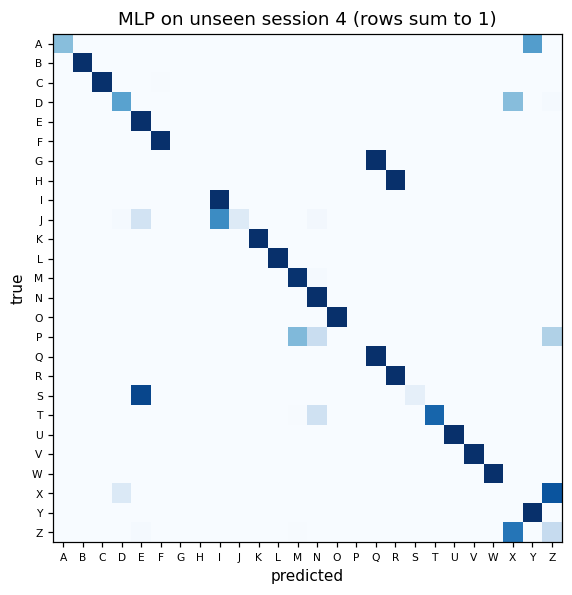

weakest letters (F1): [('G', 0.0), ('H', 0.0), ('P', 0.0), ('X', 0.0), ('S', 0.16), ('Z', 0.202)]
top confusions: [('G', 'Q', 1.0), ('H', 'R', 1.0), ('S', 'E', 0.913), ('X', 'Z', 0.86), ('Z', 'X', 0.733), ('J', 'I', 0.647)]


In [4]:
from aslcv.evaluate import metrics, latency_ms
labels = sorted(set(y))
m = metrics(y[te], model.predict(X[te]), labels)
cm = np.array(m["confusion_matrix"], float); cm /= cm.sum(1, keepdims=True).clip(min=1)
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(26), labels, fontsize=7); ax.set_yticks(range(26), labels, fontsize=7)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("MLP on unseen session 4 (rows sum to 1)")
plt.show()
print("weakest letters (F1):", sorted(m["per_letter_f1"].items(), key=lambda kv: kv[1])[:6])
print("top confusions:", [(c["true"], c["predicted"], c["rate"]) for c in m["top_confusions"][:6]])

## How light is it?

In [5]:
import io
buf = io.BytesIO(); np.savez(buf, *model.weights, *model.biases)
print(f"model size: {buf.getbuffer().nbytes / 1024:.0f} KB | one prediction: {latency_ms(model, X[te]):.3f} ms on this CPU")

model size: 72 KB | one prediction: 0.031 ms on this CPU
